# Chapter 6 : Learning Best Practices for Model Evaluation and Hyperparameter Tuning

 - Assess the performance of machine learning models
 - Diagnose the common problems of machine learning algorithms
 - Fine-tune machine learning models
 - Evaluate predictive models using different performance metrics

In [14]:
import pandas as pd 
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
import numpy as np
from sklearn.model_selection import StratifiedKFold

- Load the dataset and Handle the labels 

In [2]:
df = pd.read_csv(
    'https://archive.ics.uci.edu/ml/'
    'machine-learning-databases'
    '/breast-cancer-wisconsin/wdbc.data',
    header=None
 )

In [4]:
X = df.iloc[:,2:].values 

y = df.iloc[:,1].values 

le = LabelEncoder()

y = le.fit_transform(y)
le.classes_

array(['B', 'M'], dtype=object)

In [5]:
le.transform(["M" , "B"])

array([1, 0])

In [7]:
X_train , X_test , y_train , y_test = train_test_split(X,y , test_size= 0.20 , stratify=y , random_state=1)

-  Combining transformers and estimators in a pipeline

-  Since the features in the Breast Cancer Wisconsin dataset are measured 
    on various different scales, we will standardize the columns in the Breast Cancer Wisconsin dataset 
    before we feed them to a linear classifier, such as logistic regression.

    

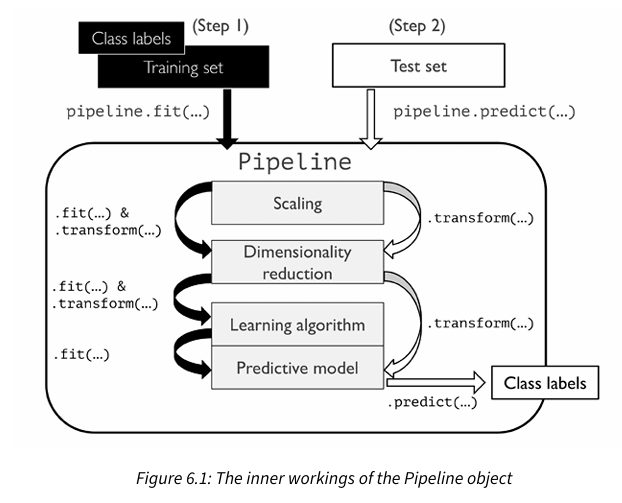

In [13]:
pipe_lr = make_pipeline(StandardScaler() , PCA(n_components=2) , LogisticRegression())

pipe_lr.fit(X_train , y_train)
y_pred = pipe_lr.predict(X_test)
test_acc = pipe_lr.score(X_test , y_test)
print(f"Test accuracy:  {test_acc:.3f}")

Test accuracy:  0.956


- Using k-fold cross-validation to assess model performance

- we are also interested in tuning and comparing different parameter settings to further improve the performance for 
    making predictions on unseen data. This process is called model selection
-  However, if we reuse the same test dataset over and over again during 
    model selection, it will become part of our training data and thus the model will be more likely to 
    overfit. Despite this issue, many people still use the test dataset for model selection

- A disadvantage of the holdout method is that the performance estimate may be very sensitive to how 
    we partition the training dataset into the training and validation subsets

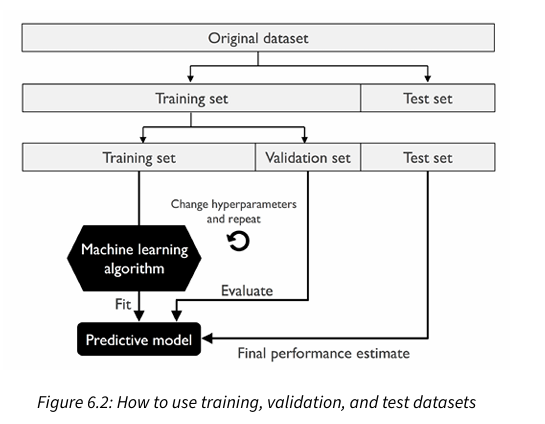

- K-fold cross-validation

-  In k-fold cross-validation, we randomly split the training dataset into k folds without replacement. 

-  average performance of the models based on the different, independent test 
    folds to obtain a performance estimate that is less sensitive to the sub-partitioning of the training data 
    compared to the holdout method.

- The rationale behind fitting a model to the whole training dataset after k-fold cross-validation is that first, 
    we are typically interested in a single, final model (versus k individual models), and second, providing 
    more training examples to a learning algorithm usually results in a more accurate and robust model.

-  A good standard value for k in k-fold cross-validation is 10, as empirical evidence shows. For instance, 
    experiments by Ron Kohavi on various real-world datasets suggest that 10-fold cross-validation offers 
    the best tradeoff between bias and variance (A Study of Cross-Validation and Bootstrap for Accuracy Esti
    mation and Model Selection by Kohavi, Ron, International Joint Conference on Artificial Intelligence (IJCAI), 
    14 (12): 1137-43, 1995, https://www.ijcai.org/Proceedings/95-2/Papers/016.pdf).


- K-fold has advantage of disjoin train and test as well as non-overlapping test sets 

- K = 10. seems to be a good standard. 



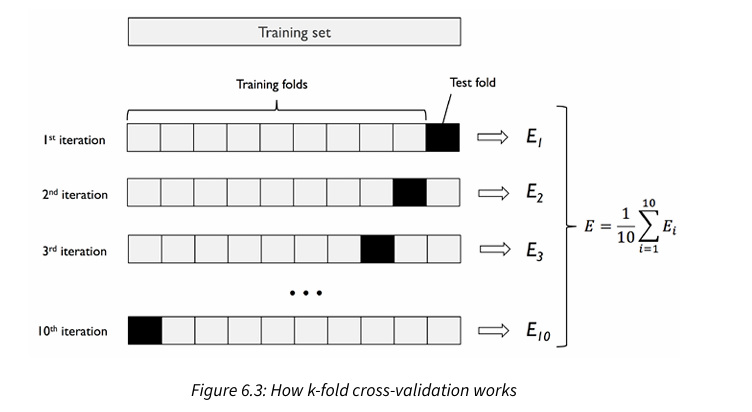

- The value of K can be incrased if if we have a relatively small dataset 

- The value of K can be decreased if we have a very Large dataset (i.e K = 5) 

- leave-one-out cross-validation (LOOCV) : is a case where k is equal to the number of trainikng eexamples we have. This is done when we have very small datasets.

- stratified k-fold cross-validation, which can yield better bias and variance estimates, especially in cases of unequal class pro
    portions. 

- In stratified cross-validation, the class label proportions are preserved in each fold to ensure 
    that each fold is representative of the class proportions in the training dataset

In [15]:

kfold = StratifiedKFold(n_splits=10).split(X_train, y_train)
scores = []
for k, (train, test) in enumerate(kfold):
      pipe_lr.fit(X_train[train], y_train[train])
      score = pipe_lr.score(X_train[test], y_train[test])
      scores.append(score)
      print(f'Fold: {k+1:02d}, '
            f'Class distr.: {np.bincount(y_train[train])}, '
            f'Acc.: {score:.3f}')

Fold: 01, Class distr.: [256 153], Acc.: 0.935
Fold: 02, Class distr.: [256 153], Acc.: 0.935
Fold: 03, Class distr.: [256 153], Acc.: 0.957
Fold: 04, Class distr.: [256 153], Acc.: 0.957
Fold: 05, Class distr.: [256 153], Acc.: 0.935
Fold: 06, Class distr.: [257 153], Acc.: 0.956
Fold: 07, Class distr.: [257 153], Acc.: 0.978
Fold: 08, Class distr.: [257 153], Acc.: 0.933
Fold: 09, Class distr.: [257 153], Acc.: 0.956
Fold: 10, Class distr.: [257 153], Acc.: 0.956


In [21]:
from sklearn.model_selection import cross_val_score 

scores = cross_val_score(estimator=pipe_lr , X = X_train , y = y_train , cv = 10 , n_jobs = 5)

print(f"CV accuracy scores: {scores}")

print(f"CV accuracy: {np.mean(scores):.3f} " f"+/-{np.std(scores):.3f}")

CV accuracy scores: [0.93478261 0.93478261 0.95652174 0.95652174 0.93478261 0.95555556
 0.97777778 0.93333333 0.95555556 0.95555556]
CV accuracy: 0.950 +/-0.014


#### Debugging algorithms with learning and validation curve

- Learning curves and validation curves. In the next 
    subsections, we will discuss how we can use learning curves to diagnose whether a learning algorithm 
    has a problem with overfitting (high variance) or underfitting (high bias). Furthermore, we will take 
    a look at validation curves, which can help us to address the common issues of learning algorithms

- High bias : Misses the mark completely 

- High Variance : large gap between the training and cross-validation accuracy

- Good Generalization 

- Learning Curve 

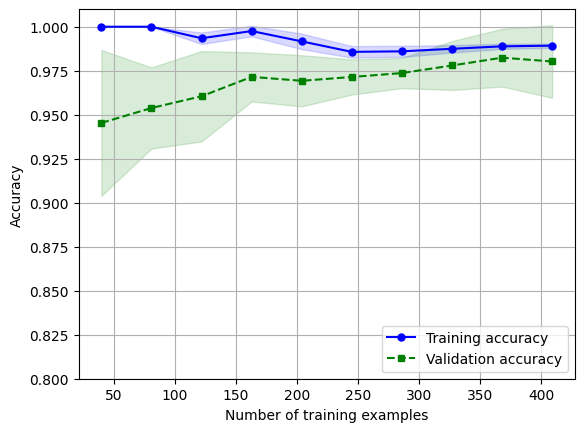

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

pipe_lr = make_pipeline(StandardScaler(),
                       LogisticRegression(penalty='l2',
                                         max_iter=10000))
train_sizes, train_scores, test_scores = \
    learning_curve(estimator=pipe_lr,
                  X=X_train,
                  y=y_train,
                  train_sizes=np.linspace(
                      0.1, 1.0, 10),
                  cv=10,
                  n_jobs=1)
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)
plt.plot(train_sizes, train_mean,
         color='blue', marker='o',
         markersize=5, label='Training accuracy')
plt.fill_between(train_sizes,
                 train_mean + train_std,
                 train_mean - train_std,
                 alpha=0.15, color='blue')
plt.plot(train_sizes, test_mean,
         color='green', linestyle='--',
         marker='s', markersize=5,
         label='Validation accuracy')
plt.fill_between(train_sizes,
                 test_mean + test_std,
                 test_mean - test_std,
                 alpha=0.15, color='green')
plt.grid()
plt.xlabel('Number of training examples')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.ylim([0.8, 1.01])
plt.show()

-  Addressing over- and underfitting with validation curves

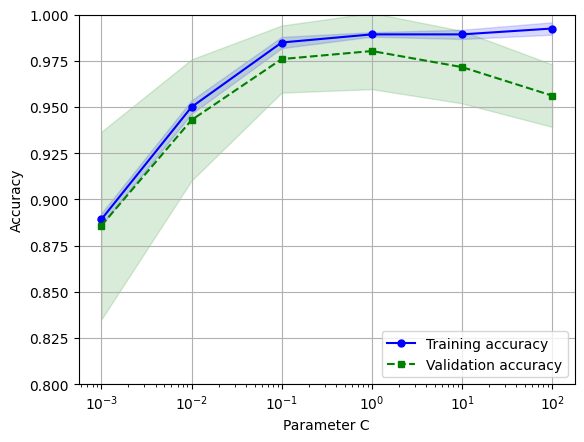

In [23]:
from sklearn.model_selection import validation_curve
param_range = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
train_scores, test_scores = validation_curve(
                estimator=pipe_lr,
                X=X_train,
                y=y_train,
                param_name='logisticregression__C',
                param_range=param_range,
                cv=10)
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)
plt.plot(param_range, train_mean,
         color='blue', marker='o',
         markersize=5, label='Training accuracy')
plt.fill_between(param_range, train_mean + train_std,
                 train_mean - train_std, alpha=0.15,
                 color='blue')
plt.plot(param_range, test_mean,
         color='green', linestyle='--',
         marker='s', markersize=5,
         label='Validation accuracy')
plt.fill_between(param_range,
                 test_mean + test_std,
                 test_mean - test_std,
                 alpha=0.15, color='green')
plt.grid()
plt.xscale('log')
plt.legend(loc='lower right')
plt.xlabel('Parameter C')
plt.ylabel('Accuracy')
plt.ylim([0.8, 1.0])
plt.show()

### Fine-tuning machine learning models via grid search

- Types of Parameters : Learnt from the training data and the ones that are optimized seperately. 

- Gridsearch : which can further help to improve the performance of a model 
    by finding the optimal combination of hyperparameter values.

- Gridsearch is a brute force approach that searches a list of parameters and evaluates all of them to find the optimal result. 


In [24]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC 

pipline_svc = make_pipeline(StandardScaler() , SVC(random_state=1))

param_range = [0.0001, 0.001, 0.01, 0.1,
                1.0, 10.0, 100.0, 1000.0]

param_grid = [{'svc__C': param_range,
                'svc__kernel': ['linear']},
                {'svc__C': param_range,
                 'svc__gamma': param_range,
                'svc__kernel': ['rbf']}]

gs = GridSearchCV(estimator=pipline_svc , 
                  param_grid=param_grid,
                  scoring= "accuracy",
                  refit = True,
                  n_jobs=1)

gs = gs.fit(X_train, y_train)

print(gs.best_score_)
print(gs.best_params_)

0.9802197802197803
{'svc__C': 1.0, 'svc__kernel': 'linear'}


In [ ]:
# # Using the independent test to evaluate the model 
# Please note that fitting a model with the best settings (gs.best_estimator_) on the training set manual
# ly via clf.fit(X_train, y_train) after completing the grid search is not necessary. The GridSearchCV 
# class has a refit parameter, which will refit the gs.best_estimator_ to the whole training set auto
# matically if we set refit=True (default)

clf = gs.best_estimator_
clf.fit(X_train , y_train)
print(f"Test accuracy: {clf.score(X_test,y_test):.3f}")

Test accuracy: 0.965


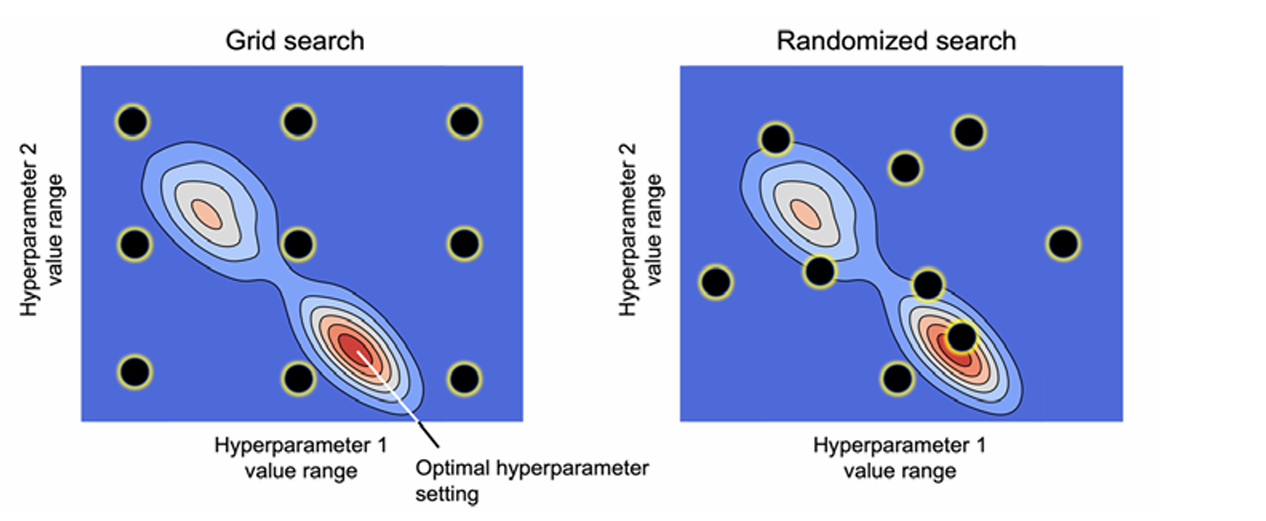

- Gridsearch is Exhausive however it is also expensive 

- Randomized search :  In randomized search, we draw hyperparameter 
    configurations randomly from distributions (or discrete sets). In contrast to grid search, randomized 
    search does not do an exhaustive search over the hyperparameter space.

-  The main takeaway is that while grid search only explores discrete, user-specified choices, it may 
    miss good hyperparameter configurations if the search space is too scarce.

-  RandomizedSearchCV supports arbitrary distributions as long as we can sample from 
    them by calling the rvs() method.

In [27]:
import scipy
np.random.seed(42)
param_range = scipy.stats.loguniform(0.0001, 1000.0)
param_range.rvs(10)

array([4.18582273e-02, 4.51856095e+02, 1.33032451e+01, 1.55099140e+00,
       1.23631883e-03, 1.23583828e-03, 2.55026485e-04, 1.15673272e+02,
       1.61363417e+00, 9.04707196e+00])

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVC 

# Now we can use distributions to specify the paramters search space and we also sepcied the numberof iterations 


pipline_svc = make_pipeline(StandardScaler() , SVC(random_state=1))

param_grid = [{'svc__C': param_range,
                'svc__kernel': ['linear']},
                {'svc__C': param_range,
                 'svc__gamma': param_range,
                'svc__kernel': ['rbf']}]

rs = RandomizedSearchCV(estimator=pipline_svc , 
                  param_distributions=param_grid,
                  scoring= "accuracy",
                  refit = True,
                  n_iter=20 , 
                  cv = 10,
                  random_state=1,
                  n_jobs=-1)

rs = rs.fit(X_train, y_train)

print(gs.best_score_)
print(gs.best_params_)

0.9802197802197803
{'svc__C': 1.0, 'svc__kernel': 'linear'}


In [34]:
clf = rs.best_estimator_
clf.fit(X_train , y_train)
print(f"Test accuracy: {clf.score(X_test,y_test):.3f}")

Test accuracy: 0.974


#### Halving RandomizedSearch 

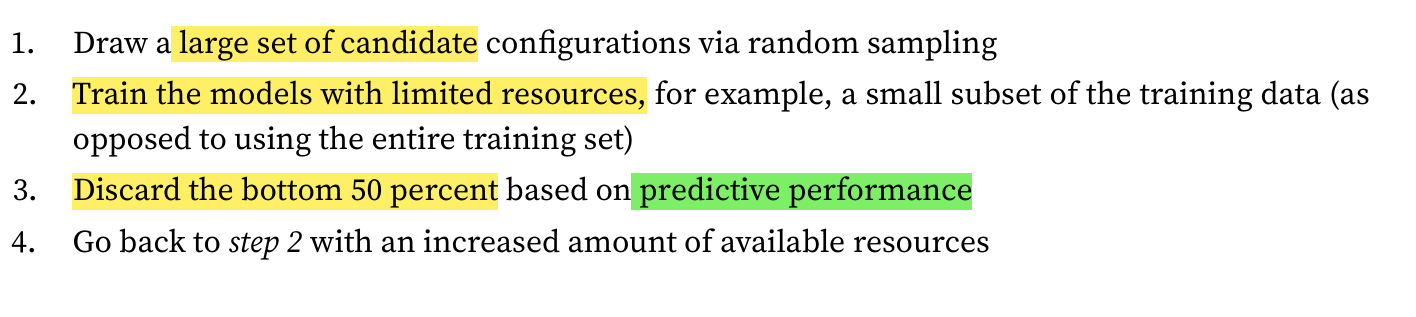

In [31]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV
hs = HalvingRandomSearchCV(pipline_svc,
                             param_distributions=param_grid,
                             n_candidates='exhaust',
                             resource='n_samples',
                             factor=1.5,
                             random_state=1,
                             n_jobs=-1)


hs = hs.fit(X_train , y_train)
print(hs.best_score_)
print(hs.best_params_)

0.9617647058823529
{'svc__C': 4.934834261073333, 'svc__kernel': 'linear'}


In [33]:
clf = hs.best_estimator_
print(f"Best paramter accuracy : {clf.score(X_test ,y_test) :.3f}")

Best paramter accuracy : 0.982


### Hyperparameter tuning with hyperopt

###  Algorithm selection with nested cross-validation

- Nested fold Cross Validation 

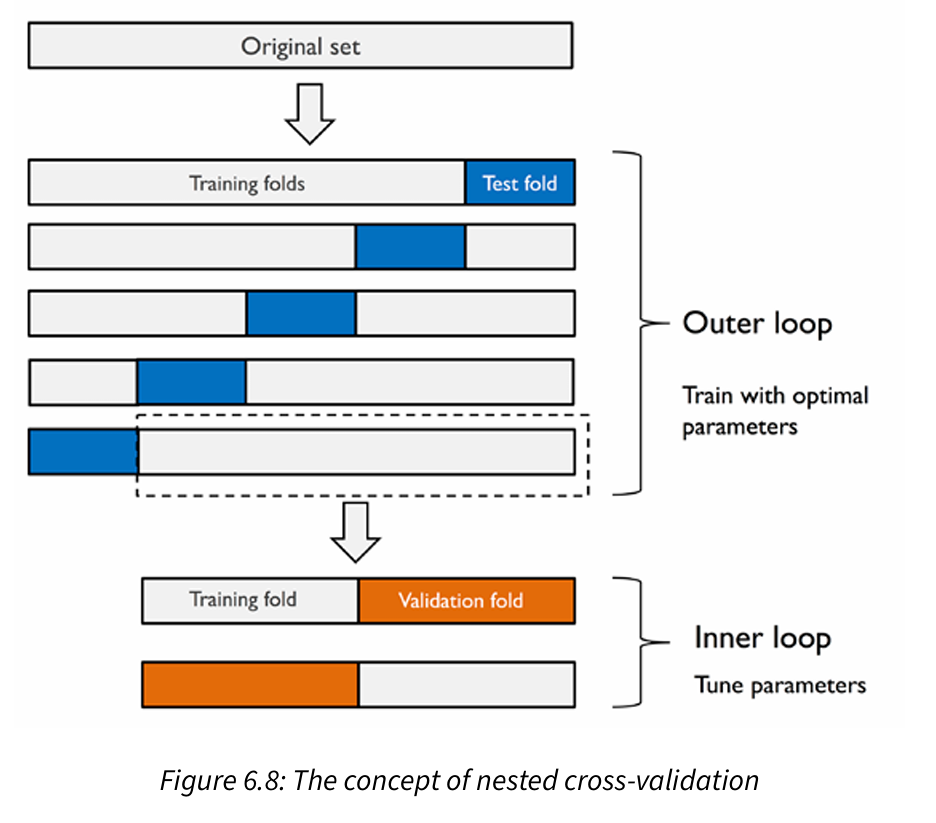

In [35]:
param_range = [0.0001, 0.001, 0.01, 0.1,1.0, 10.0, 100.0, 1000.0]

param_grid = [{'svc__C': param_range,                
                'svc__kernel': ['linear']},{'svc__C': param_range,
                'svc__gamma': param_range,
                'svc__kernel': ['rbf']}]

gs = GridSearchCV(estimator=pipline_svc,
                   param_grid=param_grid,
                   scoring='accuracy',
                   cv=2)

scores = cross_val_score(gs , X_train , y_train , scoring = "accuracy" , cv = 5)

print(f"CV Accuracy: {np.mean(scores):.3f}" f"+/-{np.std(scores):.3f}")

CV Accuracy: 0.974+/-0.015


In [36]:
from sklearn.tree import DecisionTreeClassifier
gs = GridSearchCV(
      estimator=DecisionTreeClassifier(random_state=0),
      param_grid=[{'max_depth': [1, 2, 3, 4, 5, 6, 7, None]}],
      scoring='accuracy',
      cv=2)
scores = cross_val_score(gs, X_train, y_train,
                          scoring='accuracy', cv=5)
print(f'CV accuracy: {np.mean(scores):.3f} 'f'+/- {np.std(scores):.3f}')

CV accuracy: 0.934 +/- 0.016


### Other metrices 

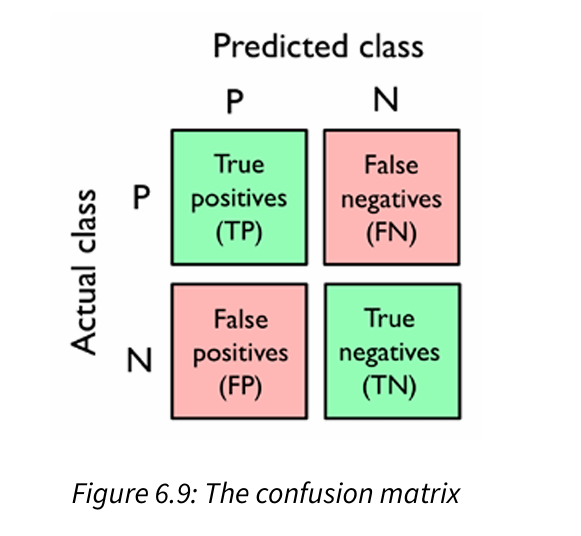

In [38]:
from sklearn.metrics import confusion_matrix 

pipline_svc.fit(X_train , y_train)
y_pred = pipline_svc.predict(X_test)
confmat = confusion_matrix(y_true = y_test , y_pred = y_pred)
print(confmat)


[[71  1]
 [ 2 40]]


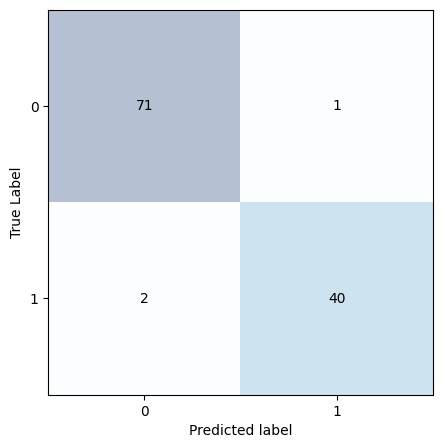

In [40]:
fig , ax = plt.subplots(figsize = (5.0 , 5.0))
ax.matshow(confmat , cmap=plt.cm.Blues , alpha = 0.3)
for i in range(confmat.shape[0]):
    for j in range(confmat.shape[0]):
        ax.text(x=j , y=i, s=confmat[i,j],va="center", ha = "center")


ax.xaxis.set_ticks_position('bottom')
plt.xlabel('Predicted label')
plt.ylabel('True Label')
plt.show()

###  Optimizing the precision and recall of a classification model

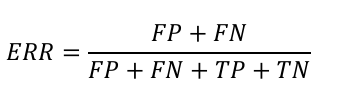

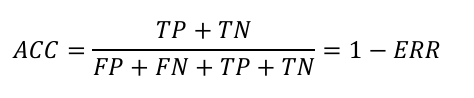

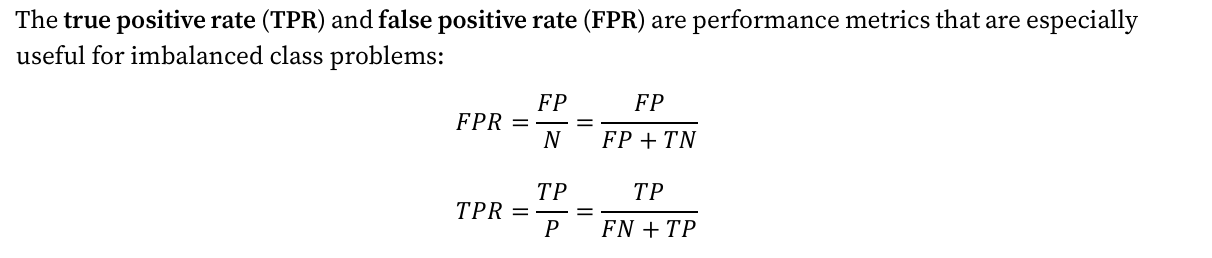

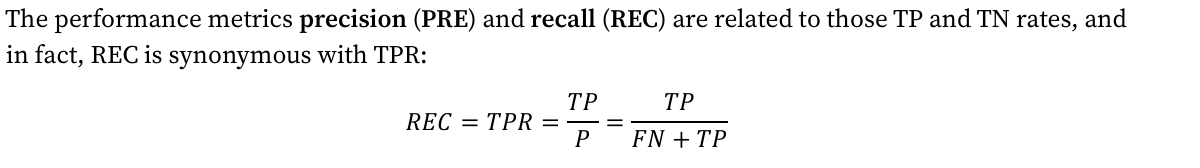

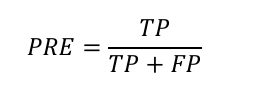

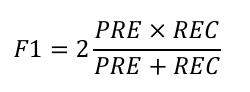

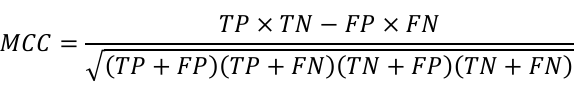

#### Precision and Recall Trade-off 

- Optimizing for Recall means we minimize the probability of not detecting the target class 

- Optimizing for Precision means we maximize correctness when we predict the target class.

In [41]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import matthews_corrcoef

pre_val = precision_score(y_true=y_test, y_pred=y_pred)
print(f'Precision: {pre_val:.3f}')
      
rec_val = recall_score(y_true=y_test, y_pred=y_pred)
print(f'Recall: {rec_val:.3f}')

f1_val = f1_score(y_true=y_test, y_pred=y_pred)
print(f'F1: {f1_val:.3f}')

mcc_val = matthews_corrcoef(y_true=y_test, y_pred=y_pred)
print(f'MCC: {mcc_val:.3f}')

Precision: 0.976
Recall: 0.952
F1: 0.964
MCC: 0.943


In [42]:
from sklearn.metrics import make_scorer

c_gamma_range = [0.01, 0.1, 1.0, 10.0]

param_grid = [{'svc__C': c_gamma_range,                
'svc__kernel': ['linear']},
{'svc__C': c_gamma_range,
 'svc__gamma': c_gamma_range,
 'svc__kernel': ['rbf']}]

scorer = make_scorer(f1_score, pos_label=0) #we made our own scorer in this case 

gs = GridSearchCV(estimator=pipline_svc,
                    param_grid=param_grid,
                    scoring=scorer,
                    cv=10)
gs = gs.fit(X_train, y_train)
print(gs.best_score_)
print(gs.best_params_)

0.9861994953378878
{'svc__C': 10.0, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}


### Plotting a receiver operating characteristic

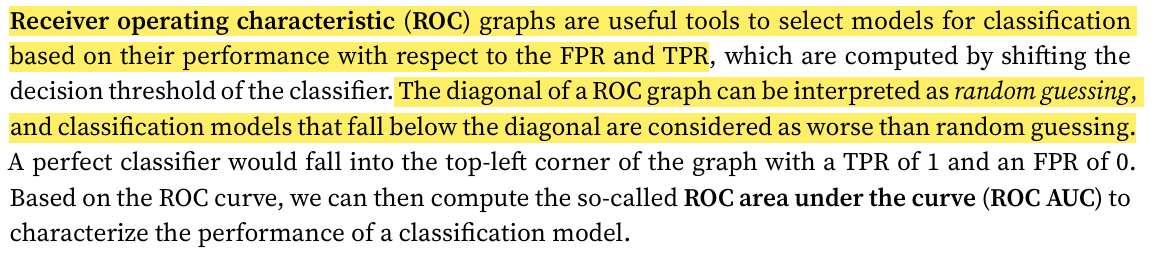

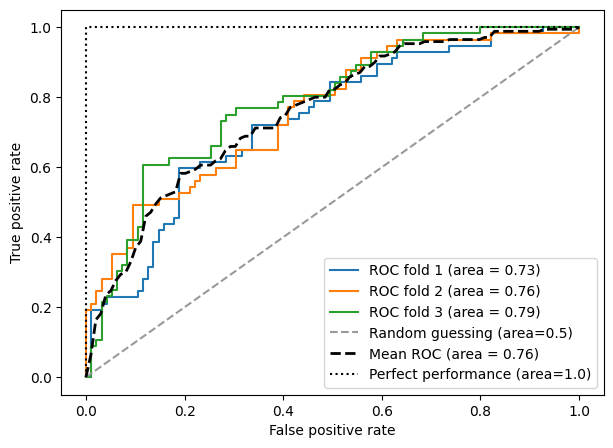

In [43]:
from sklearn.metrics import roc_curve, auc
from numpy import interp
pipe_lr = make_pipeline(
    StandardScaler(),
    PCA(n_components=2),
    LogisticRegression(penalty='l2', random_state=1,
                      solver='lbfgs', C=100.0)
)
X_train2 = X_train[:, [4, 14]]

cv = list(StratifiedKFold(n_splits=3).split(X_train, y_train))
fig = plt.figure(figsize=(7, 5))
mean_tpr = 0.0
mean_fpr = np.linspace(0, 1, 100)
all_tpr = []
for i, (train, test) in enumerate(cv):
    probas = pipe_lr.fit(
        X_train2[train],
        y_train[train]
    ).predict_proba(X_train2[test])
    fpr, tpr, thresholds = roc_curve(y_train[test],
                                    probas[:, 1],
                                    pos_label=1)
    mean_tpr += interp(mean_fpr, fpr, tpr)
    mean_tpr[0] = 0.0
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr,
            tpr,
            label='ROC fold %d (area = %0.2f)'
                  % (i+1, roc_auc))
plt.plot([0, 1],
         [0, 1],
         linestyle='--',
         color=(0.6, 0.6, 0.6),
         label='Random guessing (area=0.5)')
mean_tpr /= len(cv)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
plt.plot(mean_fpr, mean_tpr, 'k--',
         label='Mean ROC (area = %0.2f)' % mean_auc, lw=2)
plt.plot([0, 0, 1],
         [0, 1, 1],
         linestyle=':',
         color='black',
         label='Perfect performance (area=1.0)')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend(loc='lower right')
plt.show()

###  Scoring metrics for multiclass classification 

- multiclass problems via one-vs.-all (OvA) classification.

- Micro-averaging is useful if we want to weight each instance or prediction equally, whereas macro-av
    eraging weights all classes equally to evaluate the overall performance of a classifier with regard to 
    the most frequent class labels.
-  The weighted macro-average is useful if we are dealing with class imbalances, 
    that is, different numbers of instances for each label.

-  The weighted macro-average is calculated by weighting the score of each class label by the number of true instances when 
    calculating the average.





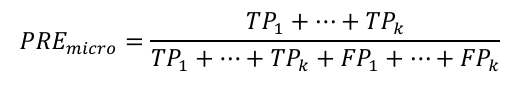

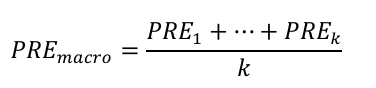

In [ ]:
# pre_scorer = make_scorer(score_func=precision_score,
#                           pos_label=1
#                           greater_is_better=True,
#                           average='micro')

#### Dealing with class imbalance

In [45]:
# lets create an unbalanced dataset 

X_imb = np.vstack((X[y == 0], X[y == 1][:40]))
y_imb = np.hstack((y[y == 0], y[y == 1][:40]))
y_pred = np.zeros(y_imb.shape[0])
np.mean(y_pred == y_imb) * 100

89.92443324937027

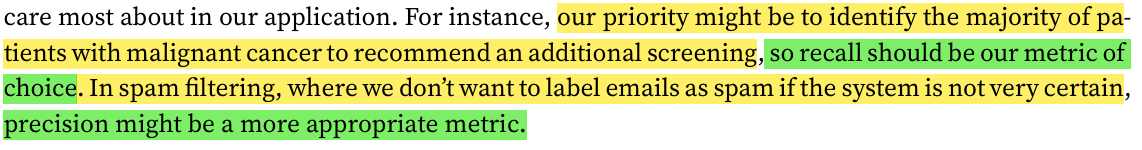

-  One way to deal with imbalanced class proportions during model fitting is to assign a larger penalty 
    to wrong predictions on the minority class.

- upsampling the minority class, downsampling the majority class, and the generation of synthetic training examples.

In [46]:
from sklearn.utils import resample
print('Number of class 1 examples before:',

       X_imb[y_imb == 1].shape[0])

X_upsampled, y_upsampled = resample(
         X_imb[y_imb == 1],
y_imb[y_imb == 1],
         replace=True,
         n_samples=X_imb[y_imb == 0].shape[0],
         random_state=123)

print('Number of class 1 examples after:',
      X_upsampled.shape[0])


Number of class 1 examples before: 40
Number of class 1 examples after: 357


In [48]:
X_bal = np.vstack((X[y == 0], X_upsampled))
y_bal = np.hstack((y[y == 0], y_upsampled))
y_pred = np.zeros(y_bal.shape[0])
np.mean(y_pred == y_bal) * 100


50.0

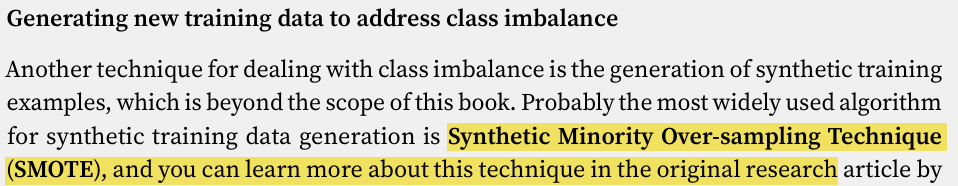